# The aquaporin family in UniProt: what the annotations tell us

**Module 02.1 · my implementation** — Seid Adem

Aquaporins are membrane channels that move water (and, for aquaglyceroporins, glycerol) across cell membranes.
Every member of the **MIP/aquaporin family (TC 1.A.8)** is expected to share two hallmarks:

* **six transmembrane helices**, and
* **two Asn-Pro-Ala (NPA) motifs** that meet in the middle of the pore and act as the selectivity filter.

This notebook pulls every **reviewed (Swiss-Prot)** member of the family from the UniProt REST API and asks:

1. Which organisms have curated aquaporins?
2. How well are the two hallmarks conserved, and what do the exceptions look like?
3. Does protein length differ between groups of organisms?
4. How much of the family has an experimental 3D structure?
5. Where in the cell are aquaporins found?

Data access uses my reusable client [`dsls.ebi_api`](../../../src/dsls/ebi_api.py) (retries, pagination, caching with provenance)
and the parser [`dsls.uniprot`](../../../src/dsls/uniprot.py); both are unit-tested in [`tests/`](../../../tests/).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from dsls.ebi_api import REPO_ROOT, uniprot
from dsls.uniprot import FIELDS, entry_to_record

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
PROCESSED = REPO_ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
GROUP_ORDER = ["Plants", "Animals", "Fungi", "Other eukaryotes", "Bacteria", "Archaea"]
PALETTE = dict(zip(GROUP_ORDER, sns.color_palette("colorblind", len(GROUP_ORDER)), strict=True))

## 1 · Retrieve the family

UniProt returns at most 500 entries per request and links to the next page in a `Link` header, so the client
walks the pages. Responses are cached in `data/raw/api_cache/uniprot/`; re-running this notebook reads them from disk
(`from_cache=True`) and gives identical results, until the cache is deleted or `refresh=True` is passed.

In [2]:
QUERY = 'family:"MIP/aquaporin (TC 1.A.8) family" AND reviewed:true'
client = uniprot()

pages = list(client.paginate("uniprotkb/search", {"query": QUERY, "fields": FIELDS, "size": 100}))
entries = [e for page in pages for e in page.json()["results"]]

first = pages[0]
provenance = {
    "query": QUERY,
    "uniprot_release": first.headers.get("x-uniprot-release"),
    "release_date": first.headers.get("x-uniprot-release-date"),
    "total_results": int(first.headers.get("x-total-results", 0)),
    "pages": len(pages),
    "entries_retrieved": len(entries),
    "fetched_at": first.fetched_at,
    "from_cache": first.from_cache,
}
assert provenance["entries_retrieved"] == provenance["total_results"], "pagination lost entries"
pd.Series(provenance, name="value").to_frame()

,value
query,"family:""MIP/aquaporin (TC 1.A.8) family"" AND r..."
uniprot_release,2026_04
release_date,04-November-2026
total_results,332
pages,4
entries_retrieved,332
fetched_at,2026-11-07T11:46:15+00:00
from_cache,True


## 2 · Tabulate the annotations

One row per protein, flattened from UniProt's nested JSON by `entry_to_record`.

In [3]:
df = pd.DataFrame(entry_to_record(e) for e in entries)
df["group"] = pd.Categorical(df["group"], categories=GROUP_ORDER)
df.to_csv(PROCESSED / "uniprot_aquaporins.csv", index=False)
print(f"{len(df)} proteins × {df.shape[1]} columns → data/processed/uniprot_aquaporins.csv")
df.head()

332 proteins × 16 columns → data/processed/uniprot_aquaporins.csv


,accession,entry_name,protein_name,gene,organism,taxon_id,group,length,is_fragment,n_transmembrane,motifs,n_npa,n_pdb,best_resolution_A,annotation_score,subcellular_locations
0,P41181,AQP2_HUMAN,Aquaporin-2,AQP2,Homo sapiens,9606,Animals,271,False,6,NPA;NPA,2,7,2.6,5.0,Apical cell membrane; Basolateral cell membran...
1,O14520,AQP7_HUMAN,Aquaporin-7,AQP7,Homo sapiens,9606,Animals,342,False,6,NPA;NPA,2,8,1.9,5.0,Cell membrane; Cytoplasmic vesicle membrane; L...
2,O43315,AQP9_HUMAN,Aquaporin-9,AQP9,Homo sapiens,9606,Animals,295,False,6,NPA;NPA,2,0,NaN,5.0,Basolateral cell membrane; Cell membrane
3,P30301,MIP_HUMAN,Lens fiber major intrinsic protein,MIP,Homo sapiens,9606,Animals,263,False,6,NPA;NPA,2,0,NaN,5.0,Cell junction; Cell membrane
4,P55087,AQP4_HUMAN,Aquaporin-4,AQP4,Homo sapiens,9606,Animals,323,False,6,NPA;NPA,2,4,1.8,5.0,Basolateral cell membrane; Cell membrane; Cell...


In [4]:
df.isna().sum().rename("missing values").to_frame().T

,accession,entry_name,protein_name,gene,organism,taxon_id,group,length,is_fragment,n_transmembrane,motifs,n_npa,n_pdb,best_resolution_A,annotation_score,subcellular_locations
missing values,0,0,0,24,0,0,0,0,0,0,15,0,0,309,0,0


## 3 · Q1 — Which organisms have curated aquaporins?

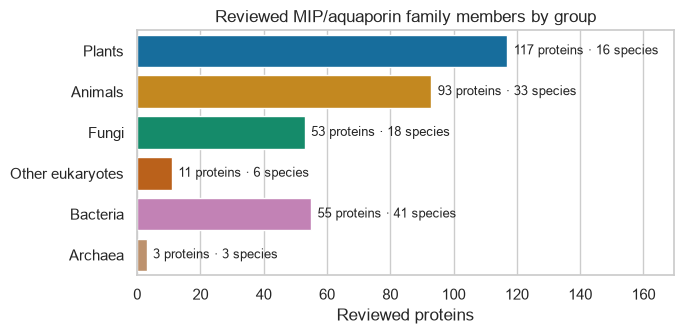

In [5]:
counts = df["group"].value_counts().reindex(GROUP_ORDER)
species = df.groupby("group", observed=True)["organism"].nunique().reindex(GROUP_ORDER)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=counts.values, y=counts.index, hue=counts.index, palette=PALETTE, legend=False, ax=ax)
for i, (n, s) in enumerate(zip(counts.values, species.values, strict=True)):
    ax.text(n + 2, i, f"{n} proteins · {s} species", va="center", fontsize=9)
ax.set(xlabel="Reviewed proteins", ylabel="", title="Reviewed MIP/aquaporin family members by group",
       xlim=(0, counts.max() * 1.45))
fig.tight_layout()
fig.savefig(FIGURES / "01_taxonomic_distribution.png", dpi=150)

In [6]:
df["organism"].value_counts().head(10).rename("proteins").to_frame()

,proteins
organism,
Arabidopsis thaliana,35
Oryza sativa subsp. japonica,33
Zea mays,32
Homo sapiens,15
Mus musculus,12
Rattus norvegicus,11
Milnesium tardigradum,11
Botrytis cinerea (strain B05.10),8
Laccaria bicolor (strain S238N-H82 / ATCC MYA-4686),7


## 4 · Q2 — Are the two hallmarks conserved?

Cross-tabulating the number of annotated NPA motifs against the number of annotated transmembrane helices.

In [7]:
pd.crosstab(df["n_npa"], df["n_transmembrane"], margins=True,
            rownames=["NPA motifs"], colnames=["transmembrane helices"])

transmembrane helices,2,3,4,5,6,7,All
NPA motifs,,,,,,,
0,5,0,0,0,9,1,15
1,1,12,5,0,9,0,27
2,0,0,0,4,276,10,290
All,6,12,5,4,294,11,332


In [8]:
canonical = (df["n_npa"] == 2) & (df["n_transmembrane"] == 6)
print(f"Both hallmarks annotated: {canonical.sum()} / {len(df)} ({canonical.mean():.0%})")

# Proteins whose annotated motifs are *not* NPA: a real biological variation, not missing data
non_canonical = df[df["motifs"].fillna("").str.contains("NPC|NPG|NPT|NPS|NPV")]
non_canonical[["accession", "gene", "protein_name", "organism", "group", "motifs", "n_transmembrane"]]

Both hallmarks annotated: 276 / 332 (83%)


,accession,gene,protein_name,organism,group,motifs,n_transmembrane
11,Q8NBQ7,AQP11,Aquaporin-11,Homo sapiens,Animals,NPC;NPA,6
57,Q8BHH1,Aqp11,Aquaporin-11,Mus musculus,Animals,NPC;NPA,6
58,Q8CHM1,Aqp11,Aquaporin-11,Rattus norvegicus,Animals,NPC;NPA,6
71,F6S3G9,AQP11,Aquaporin-11,Equus caballus,Animals,NPC;NPA,6
221,B7XIC4,AQP,Aquaporin,Enterocytozoon bieneusi (strain H348),Fungi,NPA;NPG,6
234,C4VBN2,AQP,Aquaporin,Vairimorpha ceranae (strain BRL01),Fungi,NPA;NPG,6
246,Q8SRK2,AQP,Aquaporin,Encephalitozoon cuniculi (strain GB-M1),Fungi,NPA;NPG,6
255,Q1M2P4,AQP,Aquaporin,Encephalitozoon intestinalis,Fungi,NPA;NPG,6
270,Q1M1A0,AQP,Aquaporin,Encephalitozoon hellem,Fungi,NPA;NPG,6


In [9]:
# Why do the other proteins miss a hallmark? Separate incomplete sequences (UniProt "Fragment" flag)
# from complete proteins, and recompute the hallmark rate on complete sequences only.
df["hallmarks"] = canonical.map({True: "both hallmarks", False: "missing a hallmark"})
breakdown = pd.crosstab(df["hallmarks"], df["is_fragment"].map({True: "fragment", False: "complete sequence"}),
                        margins=True)
complete = df[~df["is_fragment"]]
rate = ((complete["n_npa"] == 2) & (complete["n_transmembrane"] == 6)).mean()
print(f"Among complete sequences, {rate:.0%} carry both hallmarks")
print(f"Median length: fragments {df.loc[df.is_fragment, 'length'].median():.0f} aa, "
      f"complete {complete['length'].median():.0f} aa")
breakdown

Among complete sequences, 87% carry both hallmarks
Median length: fragments 109 aa, complete 271 aa


is_fragment,complete sequence,fragment,All
hallmarks,,,
both hallmarks,276,0,276
missing a hallmark,42,14,56
All,318,14,332


## 5 · Q3 — Does protein length differ between groups?

,count,min,50%,max
group,,,,
Plants,117.0,237.0,282.0,323.0
Animals,93.0,109.0,271.0,696.0
Fungi,53.0,149.0,311.0,724.0
Other eukaryotes,11.0,258.0,294.0,603.0
Bacteria,55.0,79.0,236.0,289.0
Archaea,3.0,246.0,246.0,246.0


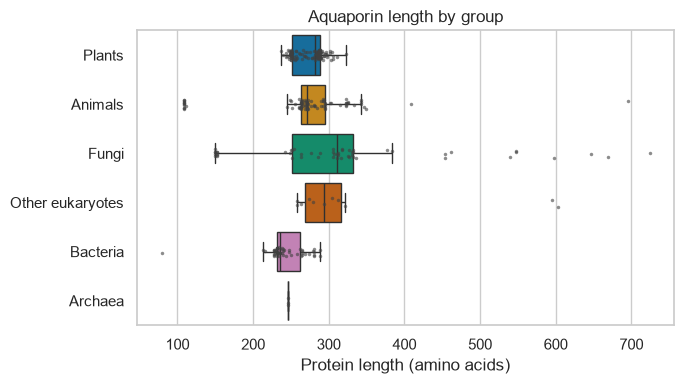

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
present = [g for g in GROUP_ORDER if (df["group"] == g).any()]
sns.boxplot(data=df, x="length", y="group", order=present, hue="group", palette=PALETTE,
            legend=False, showfliers=False, ax=ax)
sns.stripplot(data=df, x="length", y="group", order=present, color="0.25", size=2.5, alpha=0.6, ax=ax)
ax.set(xlabel="Protein length (amino acids)", ylabel="", title="Aquaporin length by group")
fig.tight_layout()
fig.savefig(FIGURES / "02_length_by_group.png", dpi=150)
df.groupby("group", observed=True)["length"].describe()[["count", "min", "50%", "max"]].round(0)

## 6 · Q4 — How much of the family has an experimental 3D structure?

In [11]:
with_structure = df[df["n_pdb"] > 0].sort_values("n_pdb", ascending=False)
print(f"{len(with_structure)} / {len(df)} proteins ({len(with_structure) / len(df):.0%}) have at least one PDB entry; "
      f"{df['n_pdb'].sum()} PDB entries in total")
with_structure[["accession", "gene", "organism", "group", "n_pdb", "best_resolution_A"]].head(15)

23 / 332 proteins (7%) have at least one PDB entry; 89 PDB entries in total


,accession,gene,organism,group,n_pdb,best_resolution_A
27,P60844,aqpZ,Escherichia coli (strain K12),Bacteria,11,1.90
5,P29972,AQP1,Homo sapiens,Animals,10,2.30
1,O14520,AQP7,Homo sapiens,Animals,8,1.90
0,P41181,AQP2,Homo sapiens,Animals,7,2.60
47,Q6J8I9,MIP,Ovis aries,Animals,7,1.90
13,P0AER0,glpF,Escherichia coli (strain K12),Bacteria,6,2.10
56,Q6ZXT3,AQP2,Trypanosoma brucei brucei,Other eukaryotes,6,2.45
32,P47862,Aqp3,Rattus norvegicus,Animals,6,2.67
6,P55064,AQP5,Homo sapiens,Animals,4,2.00
4,P55087,AQP4,Homo sapiens,Animals,4,1.80


In [12]:
with_structure.groupby("group", observed=True).agg(proteins=("accession", "size"), pdb_entries=("n_pdb", "sum"))

,proteins,pdb_entries
group,,
Plants,3,4
Animals,13,57
Other eukaryotes,2,7
Bacteria,3,18
Archaea,2,3


## 7 · Q5 — Where in the cell are aquaporins found?

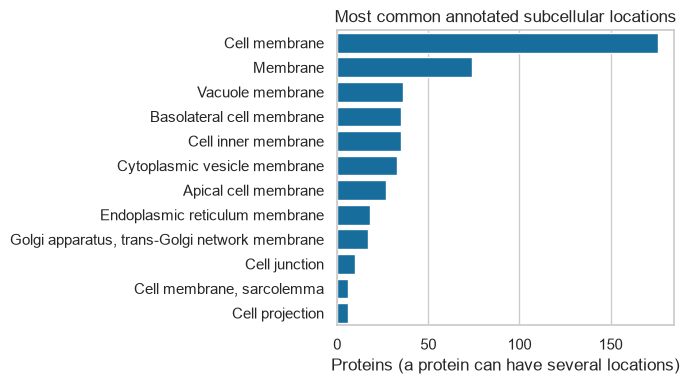

In [13]:
locations = (df["subcellular_locations"].dropna().str.split("; ").explode().value_counts().head(12))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=locations.values, y=locations.index, color=sns.color_palette("colorblind")[0], ax=ax)
ax.set(xlabel="Proteins (a protein can have several locations)", ylabel="",
       title="Most common annotated subcellular locations")
fig.tight_layout()
fig.savefig(FIGURES / "03_subcellular_locations.png", dpi=150)

In [14]:
# Plants dominate the family; which compartments do plant aquaporins use, compared with animals?
loc_long = (df.dropna(subset=["subcellular_locations"])
              .assign(location=lambda d: d["subcellular_locations"].str.split("; "))
              .explode("location"))
top = loc_long["location"].value_counts().head(6).index
pd.crosstab(loc_long["location"], loc_long["group"]).loc[top, ["Plants", "Animals", "Fungi", "Bacteria"]]

group,Plants,Animals,Fungi,Bacteria
location,,,,
Cell membrane,47,77,23,20
Membrane,30,13,30,0
Vacuole membrane,35,0,0,0
Basolateral cell membrane,0,35,0,0
Cell inner membrane,0,0,0,35
Cytoplasmic vesicle membrane,0,33,0,0


## 8 · Findings

*UniProt release 2026_04, 332 reviewed proteins.*

1. **Plants have the largest curated families, bacteria the widest spread.** Plants contribute 117 proteins from only
   16 species (35 in *Arabidopsis*, 33 in rice, 32 in maize), whereas bacteria contribute 55 proteins from 41 species,
   i.e. usually one or two per genome. A notable animal: the tardigrade *Milnesium tardigradum* has 11 reviewed
   aquaporins, as many as rat.
2. **The two hallmarks are highly conserved: 276 / 332 proteins (83 %) carry both; 87 % of complete sequences.**
   Separating the exceptions matters:
   * **All 14 UniProt-flagged fragments** miss a hallmark simply because they are incomplete. Twelve of them are the same
     109-aa stretch of AQP2 from twelve mammals, and they produce the low-length cluster in the length plot.
   * **Genuine variation:** AQP11 in four mammals has **NPC** instead of the first NPA, and five aquaporins from
     microsporidian parasites (*Encephalitozoon* and relatives, classified under Fungi by UniProt) have **NPG** in place of
     the second. These are documented non-canonical selectivity filters, not data errors.
   * The remaining ~30 complete proteins lack an *annotated* helix or motif. From annotations alone I can't tell an
     annotation gap from a truly missing feature; a sequence-level motif scan is the natural follow-up.
3. **Length is conserved around the ~270-aa channel core** (median 271 aa). Bacterial members are the most compact
   (median 236 aa). Fungi are the most variable, up to 724 aa (e.g. yeast Fps1, 669 aa); with six helices in every case,
   the extra length presumably lies in long terminal extensions beyond the core.
4. **Structural coverage is thin and skewed.** Only 23 proteins (7 %) have any PDB entry (89 entries in total), led by
   *E. coli* AqpZ and human AQP1/AQP7. Animals account for 57 of the PDB entries, but plants, which have the most proteins,
   have structures for just 3. Predicted structures (AlphaFold DB) would be the way to study the rest.
5. **The plasma membrane is universal, but compartments differ by lineage.** The vacuole membrane appears only in plants
   (35 proteins, the tonoplast aquaporins). Basolateral and cytoplasmic-vesicle membranes appear only in animals,
   consistent with polarised epithelia and regulated trafficking (e.g. kidney AQP2). Bacterial members sit in the inner
   membrane.

**What I practised:** paginated REST queries with retries and caching, flattening nested JSON into a tidy table,
and checking an expected biological pattern while separating data artefacts (fragments, annotation gaps) from real
biology (NPC/NPG variants).

**Next:** scan the sequences themselves for NPA-like motifs; add AlphaFold DB coverage; break plants down into their
PIP / TIP / NIP / SIP subfamilies.

## Reproducibility & FAIR notes

* **Findable / accessible:** every number above comes from one documented query to the public UniProt REST API;
  the release used is recorded in the provenance table (section 1).
* **Reusable raw data:** the exact API responses are cached in `data/raw/api_cache/uniprot/`, each with a
  `.meta.json` file (request URL, fetch time, UniProt release). The flattened table is written to
  `data/processed/uniprot_aquaporins.csv`. Neither is committed (see the repository's data policy).
* **Re-run:** `make lab`, open this notebook with the *EMBL-EBI DS* kernel, *Run All*. To pull a newer UniProt release,
  delete the cache folder.
* **Data licence:** UniProt data is available under [CC BY 4.0](https://www.uniprot.org/help/license).